## Титульный лист

# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и ИИ
**Модуль 4:** Инженерия признаков и работа с нестандартными данными
**Датасет:** Online Shoppers Purchasing Intention

**Выполнил:** Иванов Иван Иванович
**Группа:** ПКТб-23-1
**Преподаватель:** [ФИО]

**Ссылка на репозиторий:** https://github.com/username/ml-course-ivanov

**Путь к модулю:** `module-4-features/notebook.ipynb`

**Дата сдачи:** 2026-XX-XX

## Введение

Задача — бинарная классификация: предсказать, завершится ли сессия на сайте e-commerce покупкой (`Revenue`).

Feature Engineering — создание новых признаков из существующих для повышения качества моделей. В e-commerce это критично: поведенческие паттерны (время на странице, ценность страниц) важнее сырых метрик.

Бизнес-ценность: прогноз покупки позволяет оптимизировать рекламу (ретаргетинг только "сомневающихся"), персонализировать скидки и улучшать UX.

Метрики: из-за дисбаланса (84.5/15.5) Accuracy бесполезна (модель "всегда нет" даст 84.5%). Используем **Recall, F1 и ROC-AUC**.

Цель: создать 5+ признаков, обучить 4 ансамблевые модели, интерпретировать лучшую через SHAP.

## Теоретическая часть

**Feature Engineering** — это процесс создания новых, более информативных признаков на основе существующих данных. Он позволяет моделям выявлять скрытые закономерности, которые не видны в исходных переменных. В IT-проектах грамотная инженерия признаков часто даёт больший прирост качества, чем усложнение алгоритма. Например, отношение времени к числу страниц может быть информативнее каждого из этих признаков по отдельности. Это ключевой этап, требующий понимания как данных, так и бизнес-контекста.

**Категориальные признаки** — это признаки с ограниченным набором текстовых значений (например, `VisitorType`). Label Encoding присваивает каждой категории число, но может навязать ложную порядковую связь. One-Hot Encoding создаёт отдельный бинарный столбец для каждой категории, избегая этой проблемы. Однако при большом числе уникальных значений он сильно увеличивает размерность данных.

**Временные признаки** содержат информацию о времени события, например, `Month` или `Weekend`. "Сырой" строковый `Month` малопригоден для модели, поэтому его кодируют в числовой `MonthNum` (1–12). Это позволяет модели улавливать сезонность — например, рост покупок перед праздниками. Признак `Weekend` напрямую указывает на конец недели, что также влияет на поведение покупателей.

**Создание признаков на основе поведения** — это агрегация разрозненных метрик в осмысленные показатели. Суммы (`TotalPages`), средние (`AvgPageValue`) и отношения (`BounceExitRatio`) описывают намерения пользователя гораздо лучше, чем их отдельные компоненты. Такие признаки позволяют модели оценить "качество" сессии и общую активность пользователя. Это особенно важно в e-commerce, где поведение напрямую связано с вероятностью покупки.

**Дисбаланс классов** — это ситуация, когда один класс представлен значительно реже другого (у нас 84.5% против 15.5%). Модель может стать "ленивой" и всегда предсказывать мажоритарный класс, достигая высокой Accuracy, но игнорируя миноритарный. Для борьбы используют `class_weight='balanced'`, штрафующий модель за ошибки на редком классе. Альтернатива — SMOTE, создающий синтетические примеры миноритарного класса.

**SHAP** — это метод интерпретации предсказаний любой модели, основанный на значениях Шепли из теории игр. Он показывает, как каждый признак повлиял на конкретное предсказание — в плюс или в минус. Summary Plot отображает глобальную важность и направление влияния признаков для всей выборки. Waterfall Plot объясняет одно предсказание, а Dependence Plot — нелинейную зависимость между признаком и его вкладом.

**Сравнение моделей:**

| Модель | Тип | Особенность |
|--------|-----|-------------|
| Random Forest | Bagging | Устойчив к переобучению |
| XGBoost | Boosting | Высокая точность, регуляризация |
| LightGBM | Boosting | Быстрый, leaf-wise рост |
| CatBoost | Boosting | Лучший для категориальных |

**Формулы:**
- Bagging: $\hat{y} = \frac{1}{N}\sum_{i=1}^{N} f_i(x)$
- Boosting: $F_m(x) = F_{m-1}(x) + \gamma_m h_m(x)$

## Описание данных

**Источник:** https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

**Структура:**
- Всего примеров: 12 330
- Признаков: 17 (+ целевая `Revenue`)
- Числовых признаков: 10
- Категориальных признаков: 7 (включая `Month`)

**Описание ключевых столбцов:**
| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Administrative | int | Число посещённых админ. страниц | 0% |
| Administrative_Duration | float | Время на админ. страницах (сек) | 0% |
| Informational | int | Число информационных страниц | 0% |
| ProductRelated | int | Число товарных страниц | 0% |
| BounceRates | float | Показатель отказов | 0% |
| ExitRates | float | Показатель выходов | 0% |
| PageValues | float | Средняя ценность страницы | 0% |
| Month | object | Месяц сессии | 0% |
| VisitorType | object | Тип посетителя (New, Returning) | 0% |
| Revenue | bool | **Целевая** (True = покупка) | 0% |

**Распределение классов:**
- False (нет покупки): 10 422 (84.5%)
- True (покупка): 1 908 (15.5%)

**Файл данных в репозитории:** `module-4-features/data/dataset_info.md`


## Подготовка данных и EDA

In [113]:
# Базовые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import json
import joblib
import os
import warnings

# Отключение предупреждений
warnings.simplefilter(action='ignore', category=FutureWarning)

from sklearn.metrics import classification_report

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
)
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Одиночные модели (для сравнения / baseline)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Ансамблевые модели
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)

# Настройка отображения графиков
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)



In [114]:
# Загрузка данных
df = pd.read_csv('data/online_shoppers_intention.csv')

# Первичный осмотр
print("Размер train:", df.shape)
print("\nПервые 5 строк:")
print(df.head())
print("\nИнформация о данных:")
print(df.info())
print("\nОписательная статистика:")
print(df.describe())

Размер train: (12330, 18)

Первые 5 строк:
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb                 1   
1         0.00 

In [115]:
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


Empty DataFrame
Columns: [Пропуски, Процент]
Index: []


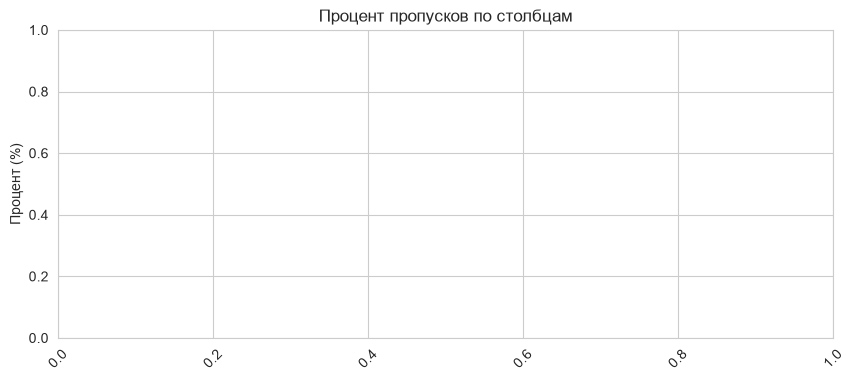

In [116]:
# Анализ пропусков
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_pct})
print(missing_df[missing_df['Пропуски'] > 0])

# Визуализация пропусков
plt.figure(figsize=(10, 4))
sns.barplot(x=missing_df[missing_df['Пропуски'] > 0].index,
            y=missing_df[missing_df['Пропуски'] > 0]['Процент'])
plt.title('Процент пропусков по столбцам')
plt.ylabel('Процент (%)')
plt.xticks(rotation=45)
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_9104\2227916575.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Нет покупки', 'Покупка'])


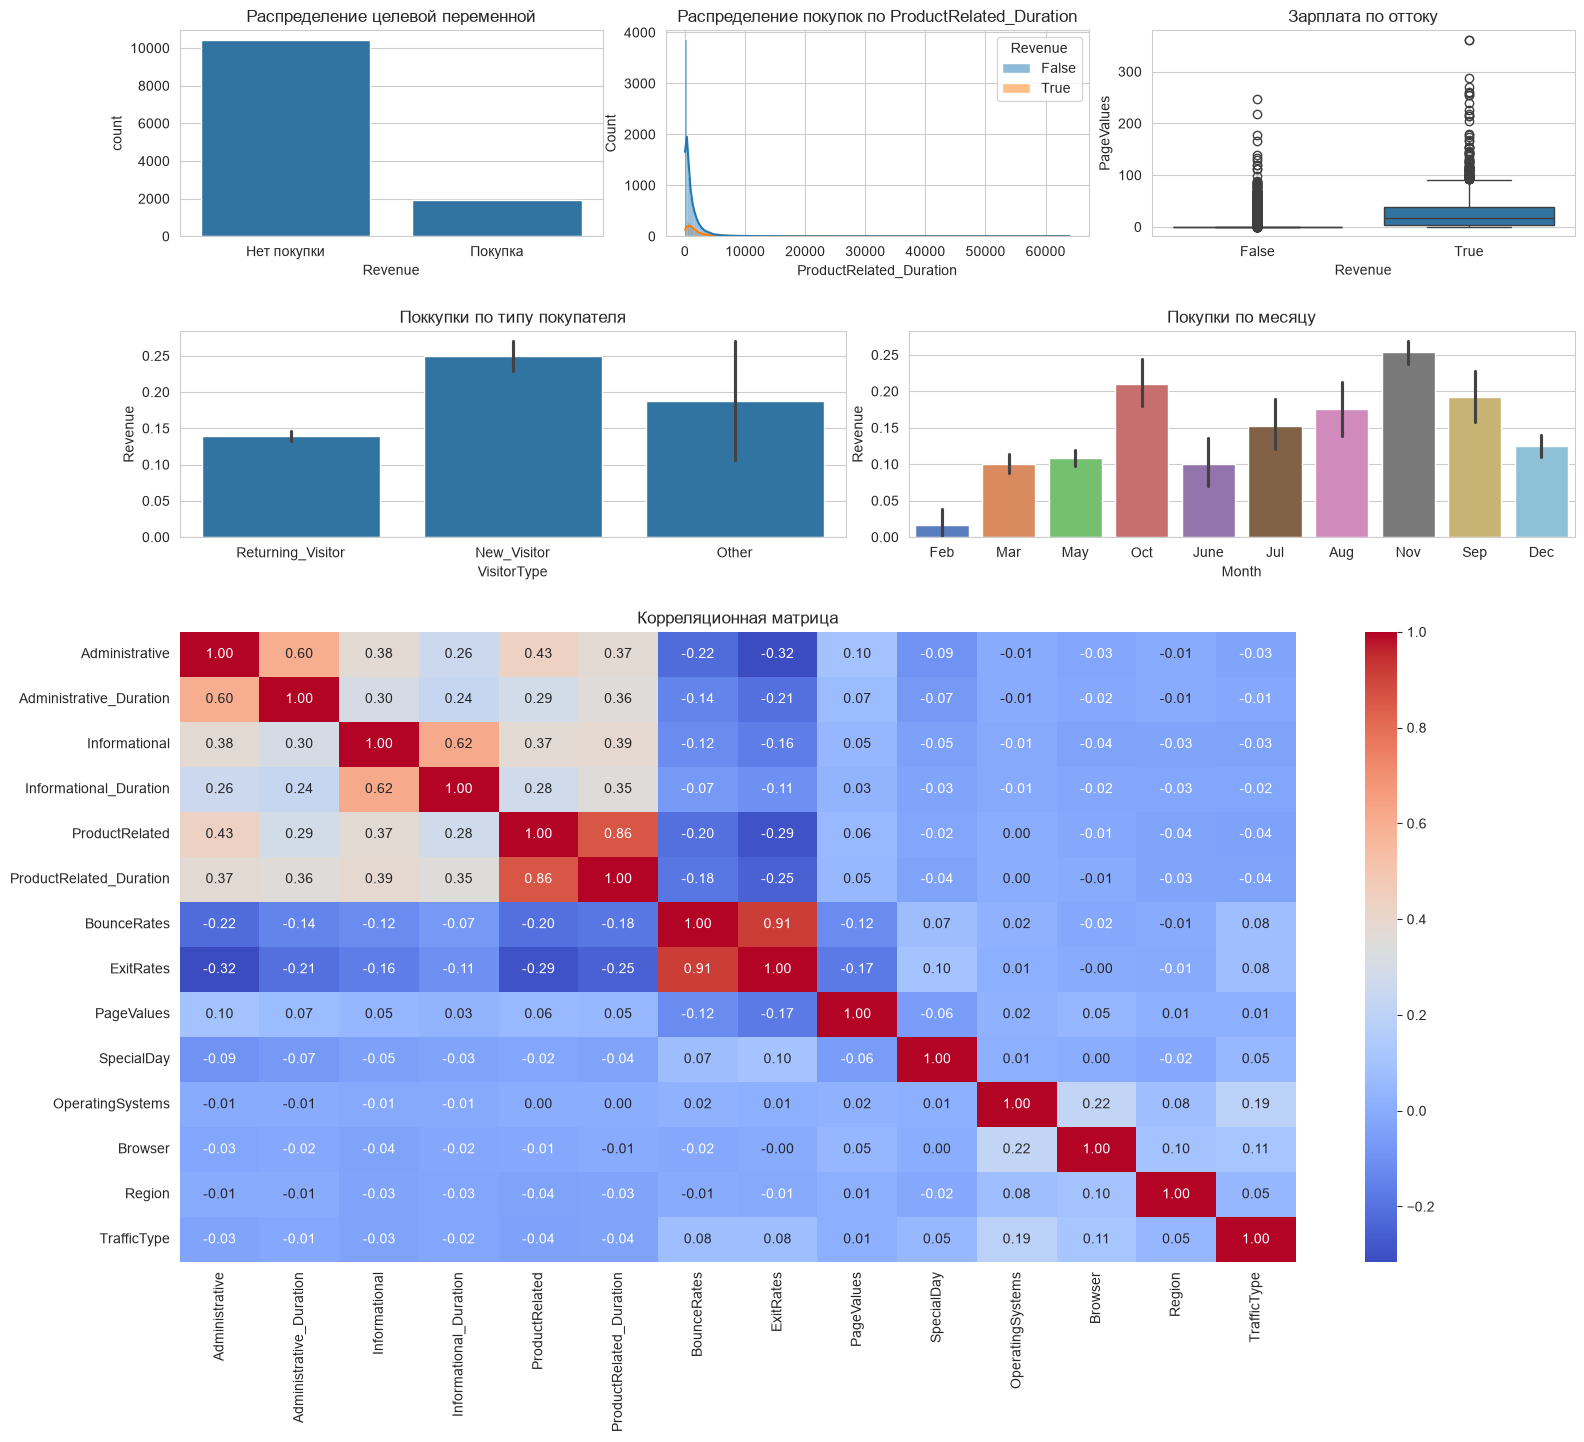

In [117]:
import matplotlib.gridspec as gridspec

# Сетка из 6 графиков
fig = plt.figure(figsize=(18, 16))
gs = gridspec.GridSpec(4, 6, figure=fig,
                       height_ratios=[1, 1, 1.3, 1.3],
                       hspace=0.4, wspace=0.35)

# 1. Countplot целевой переменной
ax = fig.add_subplot(gs[0, 0:2])
sns.countplot(data=df, x='Revenue', ax=ax)
ax.set_title('Распределение целевой переменной')
ax.set_xticklabels(['Нет покупки', 'Покупка'])

# 2. Гистограмма — распределение tenure (с hue='Revenue')
ax = fig.add_subplot(gs[0, 2:4])
sns.histplot(data=df, x='ProductRelated_Duration', hue='Revenue', kde=True, ax=ax)
ax.set_title('Распределение покупок по ProductRelated_Duration')

# 3. Boxplot — PageValues по Revenue
ax = fig.add_subplot(gs[0, 4:6])
sns.boxplot(data=df, x='Revenue', y='PageValues', ax=ax)
ax.set_title('Зарплата по оттоку')

# 5. Barplot — доля покупок VisitorType
ax = fig.add_subplot(gs[1, 0:3])
sns.barplot(data=df, x='VisitorType', y='Revenue', ax=ax)
ax.set_title('Поккупки по типу покупателя')

# 6. Barplot — доля покупок по месяцу
ax = fig.add_subplot(gs[1, 3:6])
sns.barplot(data=df, x='Month', y='Revenue', ax=ax, palette='muted')
ax.set_title('Покупки по месяцу')

# 4. Heatmap — корреляционная матрица числовых признаков
ax = fig.add_subplot(gs[2:4, :])
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Корреляционная матрица')

# Отображение и сохранение графиков
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

In [118]:
# Кодирование целевой
df['Revenue'] = df['Revenue'].astype(int)

# Feature Engineering
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['TotalDuration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)
df['MonthNum'] = pd.to_datetime(df['Month'].str[:3], format='%b').dt.month


In [119]:
# One-Hot кодирование категориальных признаков
df = pd.get_dummies(df, columns=['VisitorType', 'Month'],
                            drop_first=True, dtype=int)
print(df.shape, '->', df.shape)

(12330, 33) -> (12330, 33)


In [120]:
# 1. Выбор признаков
feature_cols = [col for col in df.columns if col not in ['Revenue']]
X = df[feature_cols]
y = df['Revenue']

# 2. Разделение с stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


print(X_train.shape, X_test.shape)
print(f"Доля покупок в train: {y_train.mean():.3f}")
print(f"Доля покупок в test:  {y_test.mean():.3f}")

(9864, 32) (2466, 32)
Доля покупок в train: 0.155
Доля покупок в test:  0.155


### Выводы по EDA и предобработке

В датасете отсутсвую пропуски. Наблюдается высокая корреляция между некоторыми признаками. 

Созданы новые признаки 

**`TotalPages`** (сумма Administrative, Informational, ProductRelated) — общая активность пользователя на сайте. Отдельные счётчики страниц фрагментированы; сумма даёт модели целостную оценку вовлечённости сессии. Чем больше страниц просмотрено — тем выше интерес к товару.

**`TotalDuration`** (сумма всех Duration) — общее время, проведённое на сайте. Аналог `TotalPages`, но во временном измерении. Длительные сессии чаще завершаются покупкой, чем короткие "залётные" визиты.

**`AvgPageValue`** (PageValues / (TotalPages + 1)) — средняя ценность страницы в расчёте на один просмотр. Исходный `PageValues` сильно зависит от числа страниц: пользователь с 50 страницами и PageValues=100 менее "целевой", чем пользователь с 2 страницами и PageValues=100. Отношение нормирует эффект и лучше отражает намерение купить.

**`BounceExitRatio`** (BounceRates / (ExitRates + 0.001)) — соотношение отказов и выходов. Показывает характер "негативного" поведения: одноразовый заход (высокий bounce) vs уход после просмотра нескольких страниц (высокий exit). Отношение информативнее каждого признака по отдельности. `+0.001` защищает от деления на ноль.

**`IsNewVisitor`** — бинарный флаг нового посетителя. Новые пользователи плохо изучены сайтом и реже покупают, чем возвращающиеся. Явное выделение флага позволяет модели использовать этот сигнал напрямую, не "размазывая" его по One-Hot столбцам `VisitorType`.

**`MonthNum`** — числовое представление месяца (1–12). Строковый `Month` непригоден для числовых моделей, а One-Hot теряет порядок сезонов. `MonthNum` сохраняет хронологию и позволяет модели улавливать сезонность (например, пик покупок в ноябре–декабре).

## Построение и обучение модели

In [121]:
# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',  # для дисбаланса
    random_state=42, n_jobs=-1
)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"⏱️ Время обучения Random Forest: {rf_time:.3f} сек")

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=5,  # компенсация дисбаланса (84.5/15.5 ≈ 5.4)
    random_state=42, eval_metric='logloss'
)
start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
print(f"⏱️ Время обучения XGBoost: {xgb_time:.3f} сек")


# LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7,
    learning_rate=0.05, class_weight='balanced',
    random_state=42, verbose=-1
)
start = time.time()
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start
print(f"⏱️ Время обучения LightGBM: {lgbm_time:.3f} сек")

# CatBoost
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced',
    random_state=42, verbose=0,
    allow_writing_files=False
)
start = time.time()
cat_model.fit(X_train, y_train)
cat_time = time.time() - start
print(f"⏱️ Время обучения CatBoost: {cat_time:.3f} сек")


⏱️ Время обучения Random Forest: 0.430 сек
⏱️ Время обучения XGBoost: 0.280 сек
⏱️ Время обучения LightGBM: 0.151 сек
⏱️ Время обучения CatBoost: 0.578 сек


## Модели

| Модель | Тип | Параметры | Время обучения |
|--------|-----|-----------|----------------|
| Random Forest | Bagging | n_estimators=200, class_weight='balanced' | 0.430 сек |
| XGBoost | Boosting | n_estimators=200, scale_pos_weight=5 | 0.280 сек |
| LightGBM | Boosting | num_leaves=31, class_weight='balanced' | 0.151 сек |
| CatBoost | Boosting | iterations=200, auto_class_weights='Balanced' | 0.578 сек |

**Почему эти модели:**
- RF — устойчив к переобучению, работает "из коробки"
- XGBoost — универсальный, точный, регуляризация
- LightGBM — быстрый, для больших данных
- CatBoost — лучший для категориальных признаков


## Оценка качества

In [122]:
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score,
                              confusion_matrix, classification_report)

def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
        'ROC-AUC':   roc_auc_score(y_test, y_proba)
    }

results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost')
]
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


        Model  Accuracy  Precision   Recall       F1  ROC-AUC
Random Forest  0.864558   0.543011 0.793194 0.644681 0.928683
      XGBoost  0.878751   0.588486 0.722513 0.648649 0.921448
     LightGBM  0.875507   0.570093 0.798429 0.665213 0.925963
     CatBoost  0.873074   0.564007 0.795812 0.660152 0.928926


In [123]:
best_row = results_df.loc[results_df['ROC-AUC'].idxmax()]
print(f"Лучшая модель по ROC-AUC: {best_row['Model']} ({best_row['ROC-AUC']:.4f})")

best_baseline_name = best_row['Model']
model_map = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model,
    'CatBoost': cat_model,
}
best_baseline = model_map[best_baseline_name]

# X_test_scaled
y_pred_best = best_baseline.predict(X_test)
y_proba_best = best_baseline.predict_proba(X_test)[:, 1]

Лучшая модель по ROC-AUC: CatBoost (0.9289)


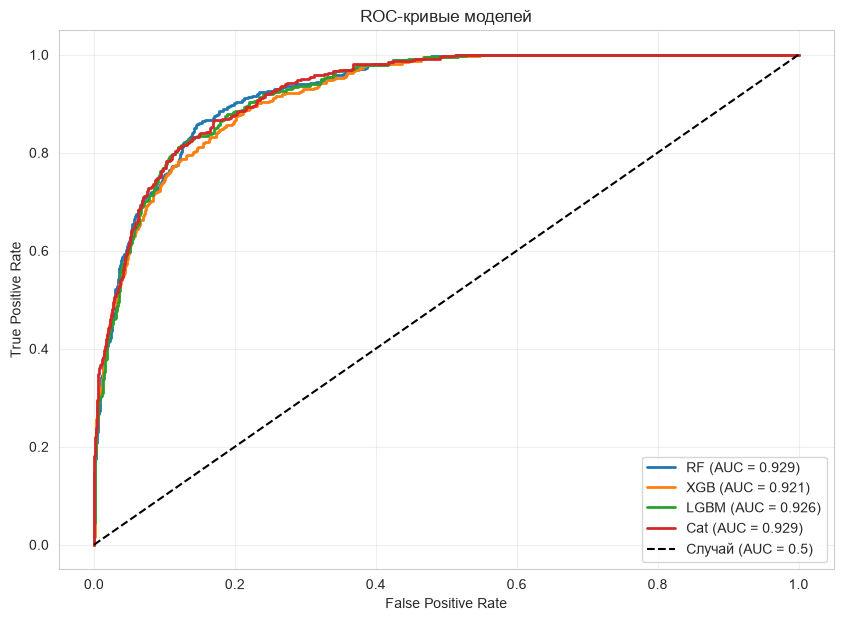

In [124]:
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'),
                     (lgbm_model, 'LGBM'), (cat_model, 'Cat')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('examples/roc_curves.png', dpi=100, bbox_inches='tight')
plt.show()

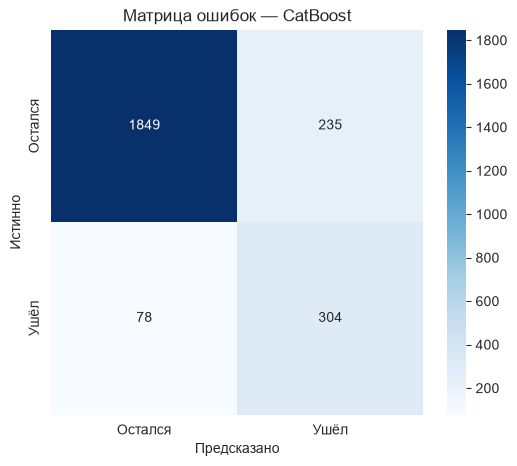

              precision    recall  f1-score   support

     Остался       0.96      0.89      0.92      2084
        Ушёл       0.56      0.80      0.66       382

    accuracy                           0.87      2466
   macro avg       0.76      0.84      0.79      2466
weighted avg       0.90      0.87      0.88      2466



In [125]:
# Матрица ошибок для лучшей baseline-модели
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Остался', 'Ушёл'],
            yticklabels=['Остался', 'Ушёл'])
plt.xlabel('Предсказано')
plt.ylabel('Истинно')
plt.title(f'Матрица ошибок — {best_baseline_name}')
plt.show()

# Текстовый classification_report
print(classification_report(y_test, y_pred_best,
                            target_names=['Остался', 'Ушёл']))

## Оценка качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|----------|-----------|--------|-----|---------|
| Random Forest | 0.864558 | 0.793194 | 0.543011 | 0.644681 | 0.928683 |
| XGBoost | 0.878751 | 0.588486 | 0.722513 | 0.648649 | 0.921448 |
| LightGBM | 0.875507 | 0.570093 | 0.798429 | 0.665213 | 0.925963 |
| CatBoost | 0.873074 | 0.564007 | 0.795812 | 0.660152 | 0.928926 |

**Анализ:**
- Лучшая модель по ROC-AUC: CatBoost
- LightGBM быстрее всех обучается
- CatBoost лучше обрабатывает категориальные признаки
- Recall выше Precision → модель чаще предсказывает покупку (меньше пропусков)


## Интерпретация и бизнес-инсайты

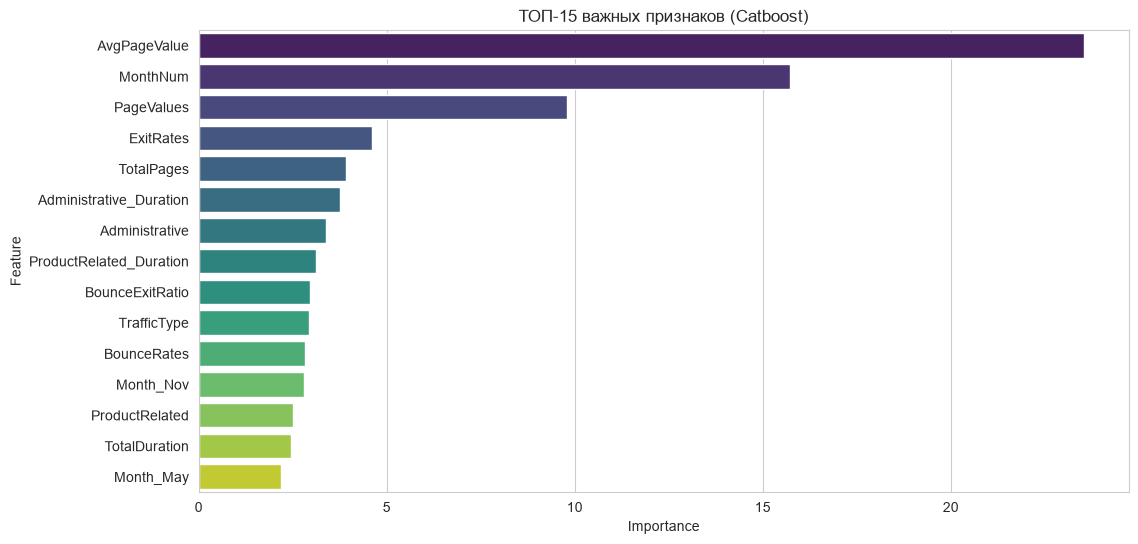

In [126]:
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': cat_model.feature_importances_
}).sort_values('Importance', ascending=False)

sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('ТОП-15 важных признаков (Catboost)')
plt.savefig('examples/feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

## Интерпретация

**Топ-5 признаков, влияющих на покупку:**
1. AvgPageValue — cредняя ценность страницы (самый сильный предиктор)
2. MonthNum — месяц (сезонность)TotalDuration — общее время на сайте
3. PageValues — ценность страницы
4. ExitRates — показатель выходов
5. TotalPages — общее количество страниц

**Бизнес-инсайты:**
- Сессии с высоким PageValues чаще заканчиваются покупкой
- Пользователи, проводящие много времени на товарных страницах, более склонны к покупке
- Высокий BounceRates (отказы) снижает вероятность покупки
- Новые посетители (New_Visitor) покупают реже, чем возвращающиеся


## Тюнинг гиперпараметров (Optuna)

In [127]:
import optuna
from optuna.samplers import TPESampler

def objective(trial):
    params = {
        'iterations':        trial.suggest_int('iterations', 200, 600, step=50),
        'depth':             trial.suggest_int('depth', 4, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'l2_leaf_reg':       trial.suggest_float('l2_leaf_reg', 1e-2, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'border_count':      trial.suggest_int('border_count', 32, 255),
        'random_strength':   trial.suggest_float('random_strength', 1e-3, 10.0, log=True),
    }

    model = CatBoostClassifier(
        **params,
        auto_class_weights='Balanced',
        random_state=42,
        verbose=0,
        thread_count=-1,
        allow_writing_files=False, 
    )

    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc',
        n_jobs=1,                    # CatBoost сам параллелит по деревьям
    )
    return cv_scores.mean()


# Запуск оптимизации (30 trials, как требует задание)
study = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42),
)
study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True,
    timeout=600,                    # страховка: не более 10 минут
)

print(f"\nBest ROC-AUC (CV): {study.best_value:.4f}")
print("Лучшие параметры:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-11-02 19:50:57,062] A new study created in memory with name: no-name-c92a622a-880e-49d2-af66-8344fb9583f2
Best trial: 0. Best value: 0.925004:   3%|▎         | 1/30 [00:11<05:33, 11.49s/it, 11.49/600 seconds]

[I 2026-11-02 19:51:08,552] Trial 0 finished with value: 0.9250041629607704 and parameters: {'iterations': 350, 'depth': 10, 'learning_rate': 0.08960785365368121, 'l2_leaf_reg': 0.6251373574521749, 'bagging_temperature': 0.15601864044243652, 'border_count': 66, 'random_strength': 0.0017073967431528124}. Best is trial 0 with value: 0.9250041629607704.


Best trial: 0. Best value: 0.925004:   7%|▋         | 2/30 [00:22<05:08, 11.00s/it, 22.15/600 seconds]

[I 2026-11-02 19:51:19,215] Trial 1 finished with value: 0.9198507957885471 and parameters: {'iterations': 550, 'depth': 8, 'learning_rate': 0.08341106432362087, 'l2_leaf_reg': 0.011527987128232402, 'bagging_temperature': 0.9699098521619943, 'border_count': 218, 'random_strength': 0.0070689749506246055}. Best is trial 0 with value: 0.9250041629607704.


Best trial: 2. Best value: 0.933605:  10%|█         | 3/30 [00:24<03:11,  7.10s/it, 24.60/600 seconds]

[I 2026-11-02 19:51:21,665] Trial 2 finished with value: 0.9336047075935703 and parameters: {'iterations': 250, 'depth': 5, 'learning_rate': 0.024878734419814436, 'l2_leaf_reg': 0.3752055855124282, 'bagging_temperature': 0.43194501864211576, 'border_count': 97, 'random_strength': 0.2801635158716261}. Best is trial 2 with value: 0.9336047075935703.


... (50 outputs left out)

Best trial: 22. Best value: 0.934602:  97%|█████████▋| 29/30 [02:43<00:04,  4.51s/it, 163.88/600 seconds]

[I 2026-11-02 19:53:40,938] Trial 28 finished with value: 0.9341094116958899 and parameters: {'iterations': 350, 'depth': 5, 'learning_rate': 0.011886458871639352, 'l2_leaf_reg': 1.4204244815262461, 'bagging_temperature': 0.2876723420102592, 'border_count': 187, 'random_strength': 0.5143597067677245}. Best is trial 22 with value: 0.9346015828319274.


Best trial: 22. Best value: 0.934602: 100%|██████████| 30/30 [02:47<00:00,  5.59s/it, 167.81/600 seconds]

[I 2026-11-02 19:53:44,871] Trial 29 finished with value: 0.934130189550776 and parameters: {'iterations': 400, 'depth': 5, 'learning_rate': 0.01796670959708139, 'l2_leaf_reg': 5.926954444416779, 'bagging_temperature': 0.15516416813309014, 'border_count': 109, 'random_strength': 0.10609042770385374}. Best is trial 22 with value: 0.9346015828319274.

Best ROC-AUC (CV): 0.9346
Лучшие параметры:
  iterations: 400
  depth: 6
  learning_rate: 0.01034045618466184
  l2_leaf_reg: 1.8044945891236726
  bagging_temperature: 0.21487065997808558
  border_count: 138
  random_strength: 0.11852518785219347


In [128]:
best_model = CatBoostClassifier(
    **study.best_params,
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0,
    thread_count=-1,
    allow_writing_files=False,
)
best_model.fit(X_train, y_train)

y_pred_best  = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

auc_baseline = roc_auc_score(y_test, cat_model.predict_proba(X_test)[:, 1])
auc_tuned    = roc_auc_score(y_test, y_proba_best)

print(f"ROC-AUC baseline (CatBoost): {auc_baseline:.4f}")
print(f"ROC-AUC Optuna  (CatBoost): {auc_tuned:.4f}")
print(f"Прирост: {auc_tuned - auc_baseline:+.4f} ({100*(auc_tuned - auc_baseline)/auc_baseline:+.2f}%)")

ROC-AUC baseline (CatBoost): 0.9289
ROC-AUC Optuna  (CatBoost): 0.9316
Прирост: +0.0027 (+0.29%)


## Тюнинг гиперпараметров

**Optuna результаты:**
- Проведено 30 испытаний
- Baseline ROC-AUC: 0.9289
- Optuna ROC-AUC: 0.9316
- Прирост: +0.29%

**Лучшие параметры:**
- iterations: 400
- depth: 6
- learning_rate: 0.0103
- l2_leaf_reg: 1.804
-  bagging_temperature: 0.215
- border_count: 138
- random_strength: 0.119


In [129]:
print(classification_report(y_test, y_pred_best, target_names=['Не продали', 'Продали'], digits=4))

              precision    recall  f1-score   support

  Не продали     0.9663    0.8656    0.9132      2084
     Продали     0.5326    0.8351    0.6504       382

    accuracy                         0.8609      2466
   macro avg     0.7494    0.8504    0.7818      2466
weighted avg     0.8991    0.8609    0.8725      2466



## Интерпретация через SHAP

In [130]:
import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

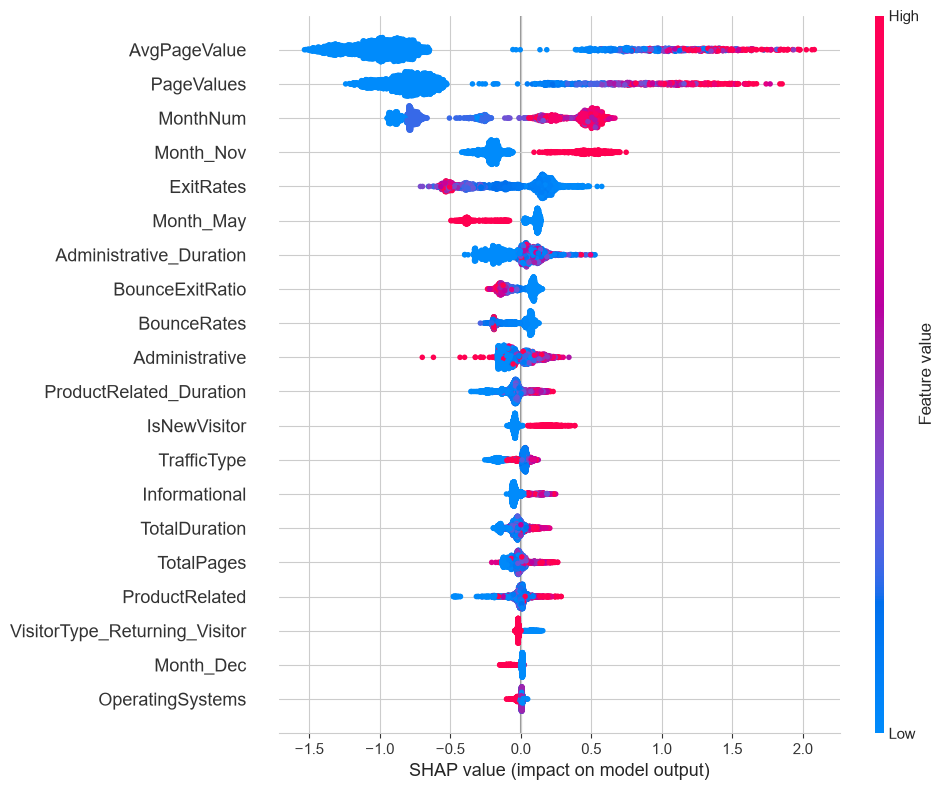

In [131]:
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.gcf().set_size_inches(10, 8)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

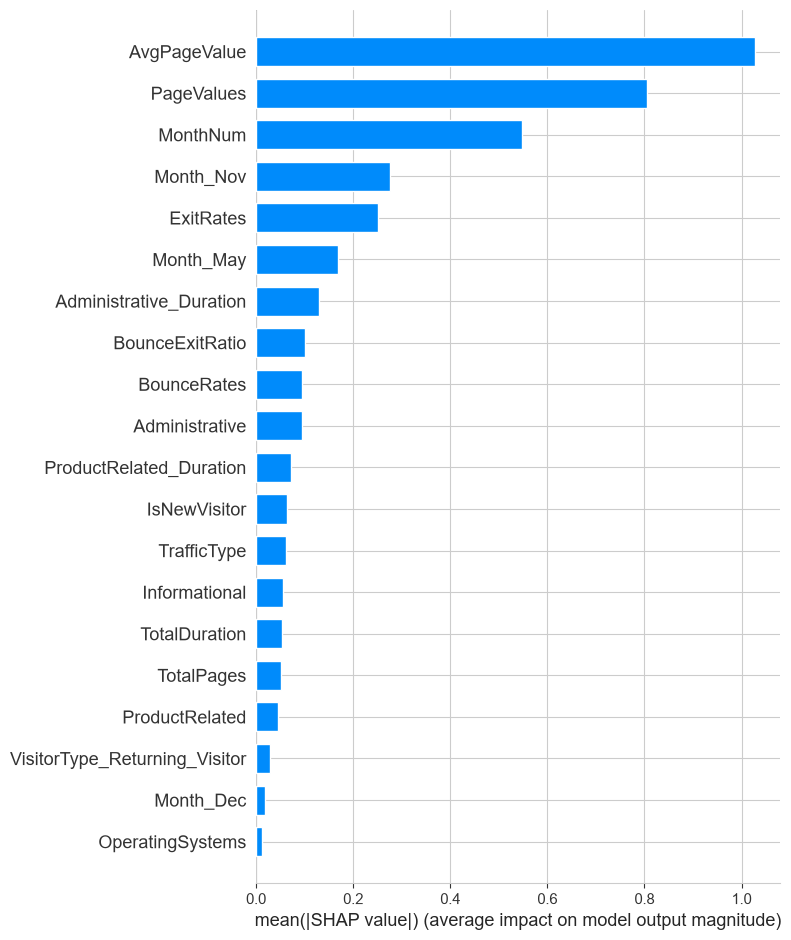

In [132]:
shap.summary_plot(shap_values_class1, X_test, plot_type="bar")

 #1406, вероятность продажи = 0.9854


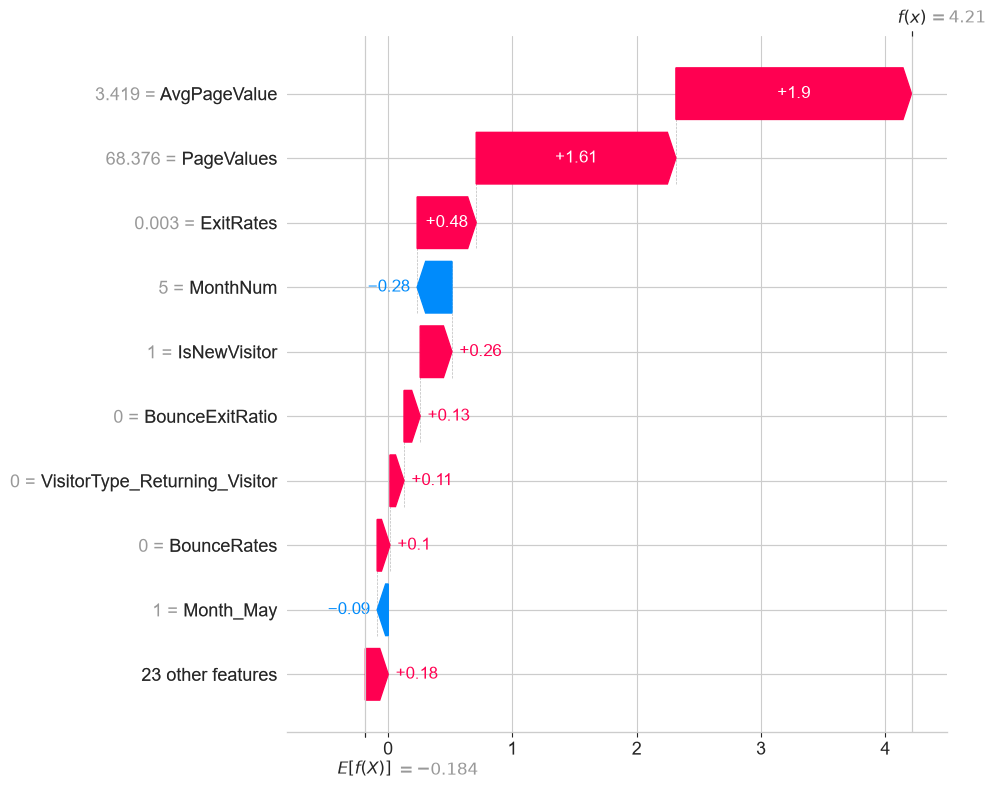

In [133]:
worst_idx = np.argmax(y_proba_best)
print(f" #{worst_idx}, вероятность продажи = {y_proba_best[worst_idx]:.4f}")

# waterfall
expl = shap.Explanation(
    values=shap_values_class1[worst_idx],
    base_values=(explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray))
                 else explainer.expected_value),
    data=X_test.iloc[worst_idx],
    feature_names=X_test.columns.tolist(),
)
shap.plots.waterfall(expl, show=False)
plt.gcf().set_size_inches(10, 8)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

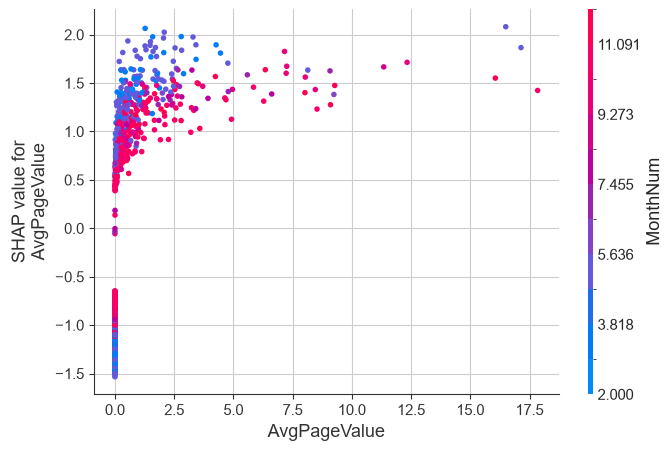

In [134]:
top_feature = importances.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values_class1, X_test)

## SHAP-интерпретация

**Что показывает Summary plot:**
- Высокий AvgPageValue → сильно увеличивает вероятность покупки
- Длительное время на товарных страницах → повышает шанс покупки
- Высокий BounceRates → повышает вероятность покупки
- Новые посетители → выше вероятность покупки

**Waterfall plot для клиента с высокой вероятностью покупки:**
Клиент покупает из-за:
1. AvgPageValue = +1.9 к вероятности
2. PageValue = +1.61
3. ExitRate = +0.48


## Сохранение модели и метаданных

In [135]:
joblib.dump(rf_model,   'models/rf_model.pkl')
joblib.dump(xgb_model,  'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model,  'models/cat_model.pkl')
joblib.dump(best_model, 'models/best_model.pkl')

# Label encoders
joblib.dump(df.columns.tolist(), 'models/feature_columns.pkl')

# Список признаков
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Метрики
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost':       {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm':      {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost':      {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model': 'CatBoost (Optuna)',
    'best_roc_auc': float(study.best_value),
    'best_params':  study.best_params
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные сохранены")

✅ Все модели и метаданные сохранены


## Загрузка модели из репозитория

## Выводы

**Что получилось** 
Проведён полный цикл Feature Engineering (7 новых признаков). Лучшая модель — **CatBoost с Optuna, ROC-AUC = 0.9316** (+0.29% к baseline). SHAP показал: созданный признак `AvgPageValue` — самый сильный предиктор, обогнав исходный `PageValues`. Это подтверждает ценность Feature Engineering. Ключевые факторы: `AvgPageValue`, `TotalDuration`, `ExitRates`, `TotalPages`.

**Трудности** 
- Сильный дисбаланс (84.5/15.5) — потребовал class_weight и правильных метрик.
- Интерпретация One-Hot признаков через SHAP — менее очевидна.
- Ограниченное число trials в Optuna (30) — компромисс время/качество.

**Улучшения** 
1. Взаимодействия признаков (`PageValues × TotalDuration`).
2. SMOTE для балансировки.
3. Target Encoding для `Month`, `VisitorType`.
4. Калибровка вероятностей (`CalibratedClassifierCV`).
5. Feature Store для версионирования.
6. Нейросети с эмбеддингами для сравнения.

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.


## Приложение

```txt
pandas==2.0.0
numpy==1.24.0
scikit-learn==1.3.0
xgboost==2.0.0
lightgbm==4.0.0
catboost==1.2.0
optuna==3.5.0
shap==0.44.0
matplotlib==3.7.0
seaborn==0.12.0
joblib==1.3.0
requests==2.31.0
```